# 3.4d — Fourier features et biais spectral : quand le MLP n'apprend pas les hautes fréquences

**Navigation** : [<< 3.4c — MoE](3.4c-MoE-from-scratch.ipynb) · [3.5-Phenomenes-de-Generalisation >](3.5-Phenomenes-de-Generalisation.ipynb) · [Feuille de route de la série](README.md) | [jumeau Python](3.4d-Fourier-Features-Biais-Spectral-Python.ipynb)

Les notebooks 3.1 à 3.4 ont construit un MLP pas à pas, l'ont armé d'Adam, et l'ont transporté jusqu'à un mini-Transformer. Sur tout ce parcours, le réseau était testé sur des tâches *algorithmiques* : classification d'un modulo, inversion de séquence, prédiction de jeton. Ces tâches ont un point commun : elles ne **ressemblent pas** à un signal — elles ont une structure symbolique, et le réseau la découvre ou la mémorise.

Ici, on revient au **signal** : une cible continue $y(x)$, où $x \in [-1, 1]$. La question est plus traîtresse qu'elle n'en a l'air :

1. Peut-on faire apprendre à un MLP tanh une **fréquence de 13 cycles** sur l'intervalle [-1, 1] ?
2. Si on lui donne la **bonne base** — un mapping $\gamma(x)$ qui projette $x$ sur des cosinus et sinus à des fréquences adaptatives — change-t-on la donne ?
3. Combien de bandes faut-il ? Que se passe-t-il si on en met trop ? Trop peu ?

Le mapping $\gamma(x) = [\cos(2\pi B x), \sin(2\pi B x)]$, popularisé par Mildenhall et al. (2020) en **NeRF** sous le nom de *positional encoding*, puis formalisé par Tancik et al. (2020) pour l'étude du **biais spectral** des réseaux de neurones, est l'outil central de ce notebook. C'est le **même geste** que les encodages positionnels sinusoïdaux du [3.4-Attention-Transformer](3.4-Attention-Transformer-From-Scratch.ipynb), transposé ici en **carte de sortie** d'une couche sans paramètres, et opposé frontalement à un MLP qui reçoit $x$ brut.

Ce qu'on cherche à voir, au-delà du MLP qui plafonne : la transition **continue** entre trois régimes — sous-ajustement (bandes trop basses), ajustement (bandes à la bonne échelle), aliasing (bandes trop hautes). Trois valeurs de $\sigma$, une seule métrique (MSE test), une seule figure.

**Kernel** : .NET C# · **Bibliothèques** : BCL · **CPU** : oui · **Prérequis** : 3.1 (MLP, rétropropagation), 3.2 (Adam)

In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

// Les tirages C# sont reproductibles mais distincts de ceux de NumPy.
class Generateur
{
    private readonly Random random;
    public Generateur(int seed) { random = new Random(seed); }
    public int Entier(int max) => random.Next(max);
    public double Normal() {
        double u1 = 1.0 - random.NextDouble();
        double u2 = 1.0 - random.NextDouble();
        return Math.Sqrt(-2.0 * Math.Log(u1)) * Math.Cos(2.0 * Math.PI * u2);
    }
}

void Verifier(bool condition, string message)
{
    if (!condition) throw new InvalidOperationException(message);
}

// Un graphique SVG est construit directement à partir des séries imprimées.
string Graphique(string titre, double[] x, params (string nom, string couleur, double[] y)[] series)
{
    if (x.Length == 0 || series.Length == 0 || series.Any(s => s.y.Length != x.Length))
        throw new ArgumentException("Séries incompatibles");
    double xmin = x.Min(), xmax = x.Max();
    double ymin = series.Min(s => s.y.Min()), ymax = series.Max(s => s.y.Max());
    if (xmax == xmin) xmax = xmin + 1;
    if (ymax == ymin) { ymin -= 1; ymax += 1; }
    double marge = (ymax - ymin) * 0.05;
    ymin -= marge; ymax += marge;
    var svg = new StringBuilder();
    svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='330' viewBox='0 0 800 330' role='img'>");
    svg.Append("<rect width='800' height='330' fill='white'/><path d='M55 35 V270 H775' fill='none' stroke='black'/>");
    svg.Append($"<text x='55' y='20' font-size='14'>{System.Net.WebUtility.HtmlEncode(titre)}</text>");
    foreach (var s in series) {
        var points = new StringBuilder();
        for (int i = 0; i < x.Length; i++) {
            double px = 55 + 720 * (x[i] - xmin) / (xmax - xmin);
            double py = 270 - 235 * (s.y[i] - ymin) / (ymax - ymin);
            points.AppendFormat(CultureInfo.InvariantCulture, "{0:F2},{1:F2} ", px, py);
        }
        svg.Append($"<polyline fill='none' stroke='{s.couleur}' stroke-width='1.3' points='{points}'/>");
    }
    for (int i = 0; i < series.Length; i++)
        svg.Append($"<text x='{55 + i * 180}' y='310' fill='{series[i].couleur}' font-size='12'>{System.Net.WebUtility.HtmlEncode(series[i].nom)}</text>");
    svg.AppendFormat(CultureInfo.InvariantCulture, "<text x='55' y='288' font-size='11'>{0:G4}</text><text x='735' y='288' font-size='11'>{1:G4}</text><text x='2' y='42' font-size='11'>{2:G4}</text><text x='2' y='270' font-size='11'>{3:G4}</text></svg>", xmin, xmax, ymax, ymin);
    return svg.ToString();
}

Console.WriteLine("Référence Python citée : NumPy 2.5.2 ; calculs de ce carnet : BCL C#.");

Référence Python citée : NumPy 2.5.2 ; calculs de ce carnet : BCL C#.


In [2]:
// Hyperparametres : montage CPU-borne, le notebook execute en ~30s
int N_TR = 64;        // points d'entrainement (peu : c'est un probleme dur)
int N_TE = 400;       // points de test (grille dense)
int H = 64;           // largeur des couches cachees
int N_LAYERS = 3;     // nombre de MATRICES de poids (in->h, h->h, h->out)
                      // soit 2 couches cachees tanh + tete lineaire
int STEPS = 3000;     // pas d'optimisation Adam
int BATCH = 16;       // taille mini-batch (leger stochastique)
double LR = 1e-3;     // taux d'apprentissage Adam
int N_BANDS = 64;     // nombre de bandes Fourier B_j
double[] SIGMAS = { 1.0, 5.0, 50.0 }; // trois regimes : sous, bon, aliasing
int SEED = 0;         // graine maitresse

Verifier(N_TR == 64 && N_TE == 400 && H == 64 && N_LAYERS == 3 && STEPS == 3000 && BATCH == 16 && LR == 1e-3 && N_BANDS == 64 && SIGMAS.SequenceEqual(new double[] { 1, 5, 50 }) && SEED == 0, "Hyperparamètres inattendus");
Console.WriteLine($"Signal : {N_TR} points d'entrainement, {N_TE} de test");

Signal : 64 points d'entrainement, 400 de test


Table cible : jeu, indice, x, y


test,0,-1,0.25768707489507714


test,1,-0.9949874686716792,0.4896698859477684


test,2,-0.9899749373433584,0.6577626853659442


test,3,-0.9849624060150376,0.7506264800103437


test,4,-0.9799498746867168,0.7681652135180198


... (455 outputs left out)

entrainement,60,0.9047619047619047,0.01789418324343578


entrainement,61,0.9365079365079365,-0.08631672634867793


entrainement,62,0.9682539682539681,-1.031019911965339


entrainement,63,1,0.2576870748950775


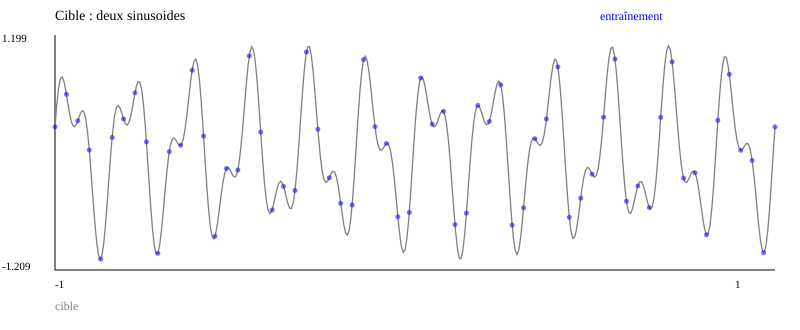

In [3]:
// Cible : somme de sinusoides haute frequence. Le MLP va peiner sur la frequence 13.
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((svg, writer) => writer.Write(svg), "image/svg+xml");
(double[] x, double[] y) MakeSignal(int n, int seed = 0)
{
    if (n < 2) throw new ArgumentException("La grille exige au moins deux points.");
    var x = new double[n];
    var y = new double[n];
    for (int i = 0; i < n; i++) {
        x[i] = i == n - 1 ? 1.0 : -1.0 + 2.0 * i / (n - 1);
        y[i] = 0.7 * Math.Sin(2 * Math.PI * 6.0 * x[i]) + 0.4 * Math.Sin(2 * Math.PI * 13.0 * x[i] + 0.7);
    }
    return (x, y);
}
// Même repère que Graphique, avec les observations d'entraînement en nuage.
string GraphiqueAvecPoints(string titre, double[] x, double[] xp, double[] yp, params (string nom, string couleur, double[] y)[] series)
{
    if (xp.Length != yp.Length || xp.Length == 0) throw new ArgumentException("Points incompatibles");
    double xmin = x.Min(), xmax = x.Max();
    double ymin = series.Min(s => s.y.Min()), ymax = series.Max(s => s.y.Max());
    if (xmax == xmin) xmax = xmin + 1;
    if (ymax == ymin) { ymin -= 1; ymax += 1; }
    double marge = (ymax - ymin) * 0.05;
    ymin -= marge; ymax += marge;
    var points = new StringBuilder();
    for (int i = 0; i < xp.Length; i++) {
        double px = 55 + 720 * (xp[i] - xmin) / (xmax - xmin);
        double py = 270 - 235 * (yp[i] - ymin) / (ymax - ymin);
        points.AppendFormat(CultureInfo.InvariantCulture, "<circle cx='{0:F2}' cy='{1:F2}' r='2.5' fill='blue' fill-opacity='0.55'/>", px, py);
    }
    points.Append("<text x='600' y='20' fill='blue' font-size='12'>entraînement</text>");
    return Graphique(titre, x, series).Replace("</svg>", points.ToString() + "</svg>");
}
var signalTr = MakeSignal(N_TR, SEED);
var signalTe = MakeSignal(N_TE, SEED + 1000);
double[] x_tr = signalTr.x, y_tr = signalTr.y;
double[] x_te = signalTe.x, y_te = signalTe.y;
Verifier(x_tr.Length == 64 && x_te.Length == 400 && x_tr[0] == -1 && x_tr[N_TR-1] == 1 && x_te[0] == -1 && x_te[N_TE-1] == 1, "Grilles incorrectes");
Verifier(Math.Abs(y_tr[0] - 0.4 * Math.Sin(0.7)) < 1e-12 && Math.Abs(y_tr[N_TR-1] - 0.4 * Math.Sin(0.7)) < 1e-12, "Signal incorrect aux bornes");
Console.WriteLine("Table cible : jeu, indice, x, y");
for (int i = 0; i < x_te.Length; i++) Console.WriteLine($"test,{i},{x_te[i]:R},{y_te[i]:R}");
for (int i = 0; i < x_tr.Length; i++) Console.WriteLine($"entrainement,{i},{x_tr[i]:R},{y_tr[i]:R}");
display(GraphiqueAvecPoints("Cible : deux sinusoides", x_te, x_tr, y_tr, ("cible", "gray", y_te)), "image/svg+xml");

## 1. Le biais spectral : le MLP n'apprend pas les hautes fréquences

**Qu'est-ce que le biais spectral ?** Rahaman et al. (2019, *On the Spectral Bias of Neural Networks*) montrent qu'un MLP à activations lisses (tanh, sin, ReLU) **converge d'abord vers les basses fréquences** de sa cible — les fonctions de la couche finale vivent dans une bande passante limitée par la *Neural Tangent Kernel* (NTK, Jacot et al. 2018), dont le spectre décroît exponentiellement avec la fréquence.

Conséquence pratique : un MLP face à un signal qui mélange des fréquences 6 et 13 cycles va **apprendre la 6, négliger la 13**, et produire une approximation visiblement *lisse* du signal. La sortie MSE reste médiocre. Augmenter la largeur, la profondeur, ou le nombre de pas d'optimisation ne change pas la structure du problème : la bande passante du NTK reste la même.

**Le mapping de Fourier $\gamma(x)$ contourne le problème.** Tancik et al. (2020, *Fourier Features Let Networks Learn High Frequency Functions in Low Dimensional Domains*) montrent qu'en passant l'entrée par

$$\gamma(x) = [\cos(2\pi B_1 x), \sin(2\pi B_1 x), \dots, \cos(2\pi B_k x), \sin(2\pi B_k x)]$$

où $B_j \sim \mathcal{N}(0, \sigma^2)$ est un vecteur de bandes aléatoires gaussiennes, on **élargit la bande passante effective** du réseau. La sortie vit dans la base $[\cos, \sin]$ des bandes données ; le MLP n'a plus qu'à apprendre l'amplitude et la phase de chaque composante, ce que tanh fait trivialement.

**Trois régimes à voir venir**, dès la formulation :

- **$\sigma$ trop petit** : les bandes $B_j$ restent concentrées près de zéro, le mapping $\gamma$ ne porte aucune information haute fréquence. Le réseau n'apprend **rien de plus** que la MLP brute — il a juste reçu des cosinus à basse fréquence en entrée.
- **$\sigma$ adapté** : les bandes couvrent (et dépassent légèrement) la fréquence dominante du signal. Le réseau apprend la cible avec une MSE test faible — c'est la *bande passante utile*.
- **$\sigma$ trop grand** : les bandes portent des fréquences très au-delà du signal. La base $\gamma$ est **redondante** (deux bandes voisines jouent des rôles quasi-identiques), le réseau **mémorise** les points d'entraînement et généralise mal. C'est l'*aliasing de capacité* : trop de bandes pour le nombre d'observations.

**Note sur la NTK et la preuve théorique.** Le théorème de Tancik et al. formalise ce passage en bande passante : pour $\sigma \to \infty$, le NTK du MLP compose avec les bandes Fourier et son spectre se *redresse* sur les hautes fréquences. Mais la preuve dit **qu'on peut** apprendre les hautes fréquences, pas **qu'on doit** en mettre le plus possible. Le bon $\sigma$ est une propriété du signal et du nombre d'observations — pas un hyperparamètre gratuit. C'est ce qu'on mesure empiriquement dans les sections 3 à 5.

**Lien NeRF.** Mildenhall et al. (2020, *NeRF: Representing Scenes as Neural Radiance Fields for View Synthesis*) utilisent $\gamma(x) = [\sin(2^0 \pi x), \cos(2^0 \pi x), \dots, \sin(2^{L-1} \pi x), \cos(2^{L-1} \pi x)]$ avec $L = 10$ sur les coordonnées 3D. Le choix $2^l$ est un cas particulier du mapping gaussien (il force un balayage **dyadique** des fréquences). C'est exactement le geste que vous avez déjà vu dans les encodages positionnels sinusoïdaux du [3.4-Attention-Transformer](3.4-Attention-Transformer-From-Scratch.ipynb) — sauf que là, l'entrée est une position de séquence, ici une coordonnée d'espace.

**Lien RoPE.** RoPE (Rotary Position Embedding, Su et al. 2021) applique une rotation 2D dans le plan complexe à chaque paire de features d'attention, indexée par la position. C'est une *encodage positionnel appliqué à la sortie d'attention*, pas à l'entrée du MLP — le mécanisme est différent mais l'esprit (faire porter la position par des sinusoïdes) est le même. Le mapping $\gamma$ ici est l'instance la plus directe.

In [4]:
// MLP tanh a 2 couches cachees (3 matrices de poids), gradient ecrit a la main (cf. 3.1)
class FourierMLP
{
    public readonly int[] dims;
    public readonly double[][] W;
    public readonly double[][] b;
    public int Layers => W.Length;

    public FourierMLP(int inDim, int h, int outDim, int nLayers, int seed)
    {
        if (nLayers < 2) throw new ArgumentException("n_layers >= 2");
        dims = new int[nLayers + 1];
        dims[0] = inDim;
        for (int l = 1; l < nLayers; l++) dims[l] = h;
        dims[nLayers] = outDim;
        W = new double[nLayers][]; b = new double[nLayers][];
        var rng = new Generateur(seed);
        for (int l = 0; l < nLayers; l++) {
            W[l] = new double[dims[l] * dims[l + 1]];
            b[l] = new double[dims[l + 1]];
            double scale = Math.Sqrt(1.0 / dims[l]);
            for (int i = 0; i < W[l].Length; i++) W[l][i] = rng.Normal() * scale;
        }
    }

    public double[][] Params()
    {
        var p = new double[2 * Layers][];
        for (int l = 0; l < Layers; l++) { p[2*l] = W[l]; p[2*l+1] = b[l]; }
        return p;
    }

    // Les activations de chaque couche servent aussi au calcul du gradient.
    public double[][] Activations(double[] x)
    {
        var a = new double[Layers + 1][];
        a[0] = x;
        for (int l = 0; l < Layers; l++) {
            int ni = dims[l], no = dims[l+1];
            a[l+1] = new double[no];
            Array.Copy(b[l], a[l+1], no);
            for (int i = 0; i < ni; i++)
                for (int j = 0; j < no; j++) a[l+1][j] += a[l][i] * W[l][i*no+j];
            if (l < Layers-1)
                for (int j = 0; j < no; j++) a[l+1][j] = Math.Tanh(a[l+1][j]);
        }
        return a;
    }

    public double[][] Forward(double[][] x)
    {
        var output = new double[x.Length][];
        for (int i = 0; i < x.Length; i++) output[i] = Activations(x[i])[Layers];
        return output;
    }

    // La cible du carnet est scalaire ; les gradients sont moyennés sur le lot.
    public (double[][] gradients, double loss) GradMse(double[][] x, double[] y)
    {
        if (dims[Layers] != 1 || x.Length != y.Length || x.Length == 0) throw new ArgumentException("Lot incompatible");
        var p = Params();
        var g = p.Select(v => new double[v.Length]).ToArray();
        double loss = 0;
        for (int k = 0; k < x.Length; k++) {
            var a = Activations(x[k]);
            double err = a[Layers][0] - y[k];
            loss += err * err;
            double[] delta = { 2.0 * err / x.Length };
            for (int l = Layers - 1; l >= 0; l--) {
                int ni = dims[l], no = dims[l+1];
                for (int j = 0; j < no; j++) g[2*l+1][j] += delta[j];
                for (int i = 0; i < ni; i++)
                    for (int j = 0; j < no; j++) g[2*l][i*no+j] += a[l][i] * delta[j];
                if (l > 0) {
                    var prev = new double[ni];
                    for (int i = 0; i < ni; i++) {
                        double sum = 0;
                        for (int j = 0; j < no; j++) sum += W[l][i*no+j] * delta[j];
                        prev[i] = sum * (1.0 - a[l][i] * a[l][i]);
                    }
                    delta = prev;
                }
            }
        }
        return (g, loss / x.Length);
    }
}

// Garde gradient (cf. 3.1) : on verifie qu'on n'a pas perdu un signe dans le backward
var modeleTest = new FourierMLP(1, 8, 1, N_LAYERS, 42);
double[][] xTestGrad = x_tr.Take(8).Select(v => new double[] { v }).ToArray();
double[] yTestGrad = y_tr.Take(8).ToArray();
var gradTest = modeleTest.GradMse(xTestGrad, yTestGrad).gradients;
var paramTest = modeleTest.Params();
var rngTest = new Generateur(0);
double ecartGradient = 0, epsGradient = 1e-3;
for (int p = 0; p < paramTest.Length; p++) {
    var indices = Enumerable.Range(0, paramTest[p].Length).ToArray();
    for (int j = indices.Length - 1; j > 0; j--) { int k = rngTest.Entier(j + 1); (indices[j], indices[k]) = (indices[k], indices[j]); }
    foreach (int i in indices.Take(Math.Min(3, indices.Length))) {
        double ancien = paramTest[p][i];
        paramTest[p][i] = ancien + epsGradient;
        double lp = modeleTest.GradMse(xTestGrad, yTestGrad).loss;
        paramTest[p][i] = ancien - epsGradient;
        double lm = modeleTest.GradMse(xTestGrad, yTestGrad).loss;
        paramTest[p][i] = ancien;
        double num = (lp - lm) / (2 * epsGradient), ana = gradTest[p][i];
        if (Math.Abs(num) + Math.Abs(ana) > 1e-9)
            ecartGradient = Math.Max(ecartGradient, Math.Abs(num - ana) / (Math.Abs(num) + Math.Abs(ana)));
    }
}
Console.WriteLine($"Ecart gradient check : {ecartGradient:E2} (seuil 1e-5)");
Console.WriteLine($"Référence Python citée : 2.08e-07 ; écart absolu : {Math.Abs(ecartGradient - 2.08e-7):E2} (tirages distincts ; tolérance 1e-5)");
Verifier(ecartGradient < 1e-5, "backward inexact");
Verifier(Math.Abs(ecartGradient - 2.08e-7) < 1e-5, "Écart gradient à la référence trop grand");

Ecart gradient check : 5.24E-007 (seuil 1e-5)


Référence Python citée : 2.08e-07 ; écart absolu : 3.16E-007 (tirages distincts ; tolérance 1e-5)


In [5]:
// Adam (cf. 3.2), en version compacte
double[] AdamTrain(FourierMLP model, double[][] x, double[] y, int steps, double lr, int batch, int seed)
{
    if (x.Length != y.Length || x.Length == 0 || batch <= 0) throw new ArgumentException("Lot incompatible");
    var p = model.Params();
    var m = p.Select(a => new double[a.Length]).ToArray();
    var v = p.Select(a => new double[a.Length]).ToArray();
    var rng = new Generateur(seed);
    var indices = Enumerable.Range(0, x.Length).ToArray();
    var losses = new double[steps];
    const double b1 = 0.9, b2 = 0.999, epsilon = 1e-8;
    double puissance1 = 1.0, puissance2 = 1.0;
    for (int step = 1; step <= steps; step++) {
        double[][] xb = x;
        double[] yb = y;
        // Comme dans la source, l'ordre courant est mélangé à chaque pas.
        if (batch < x.Length) {
            for (int i = indices.Length - 1; i > 0; i--) {
                int j = rng.Entier(i + 1);
                (indices[i], indices[j]) = (indices[j], indices[i]);
            }
            xb = new double[batch][]; yb = new double[batch];
            for (int i = 0; i < batch; i++) { xb[i] = x[indices[i]]; yb[i] = y[indices[i]]; }
        }
        var calcul = model.GradMse(xb, yb);
        losses[step - 1] = calcul.loss;
        puissance1 *= b1; puissance2 *= b2;
        for (int k = 0; k < p.Length; k++)
            for (int i = 0; i < p[k].Length; i++) {
                double g = calcul.gradients[k][i];
                m[k][i] = b1 * m[k][i] + (1 - b1) * g;
                v[k][i] = b2 * v[k][i] + (1 - b2) * g * g;
                double mh = m[k][i] / (1 - puissance1);
                double vh = v[k][i] / (1 - puissance2);
                p[k][i] -= lr * mh / (Math.Sqrt(vh) + epsilon);
            }
    }
    return losses;
}

## 2. Baseline : MLP(x) face au signal

On entraîne un MLP à **2 couches cachées** tanh (soit 3 matrices de poids : entrée→cachée, cachée→cachée, cachée→sortie), 64 neurones par couche cachée, sur le signal 1D décrit plus haut. Pas de mapping — l'entrée brute est $x \in [-1, 1]$. On s'attend à voir un **sous-ajustement des hautes fréquences** : la MSE test reste médiocre, et la prédiction est visiblement *lissée* par rapport à la cible.

Baseline : MLP 3 matrices de poids (2 couches cachees tanh), 64 neurones, 4353 parametres


Baseline : MSE test = 3.255E-001 | loss finale = 4.582E-001


Références Python citées : MSE 3.226e-01, loss 2.266e-01 ; écarts absolus 2.927E-003, 2.316E-001 ; tolérances 0.2, 0.4


Table baseline : x, cible, prediction
-1,0.25768707489507714,0.20177414686171777
-0.9949874686716792,0.4896698859477684,0.20072341604362937
-0.9899749373433584,0.6577626853659442,0.1996694601394326
-0.9849624060150376,0.7506264800103437,0.1986123009898457
-0.9799498746867168,0.7681652135180198,0.1975519612439522
-0.974937343358396,0.7209985329690308,0.19648846437412373
-0.9699248120300752,0.6282250013865267,0.19542183469115976
-0.9649122807017544,0.5138626435807016,0.19435209735964645
-0.9598997493734336,0.40256954548415746,0.19327927841353443
-0.9548872180451128,0.3153629172419934,0.19220340477193998
-0.949874686716792,0.2660515720082517,0.19112450425517133
-0.9448621553884712,0.2589748695025244,0.19004260560098152
-0.9398496240601504,0.2884211184340446,0.18895773848105069
-0.9348370927318296,0.3398167466492892,0.18786993351770048
-0.9298245614035088,0.3924809408533879,0.18677922230084132
-0.924812030075188,0.4234780980579665,0.18568563740515653
-0.9197994987468672,0.41191581528151994

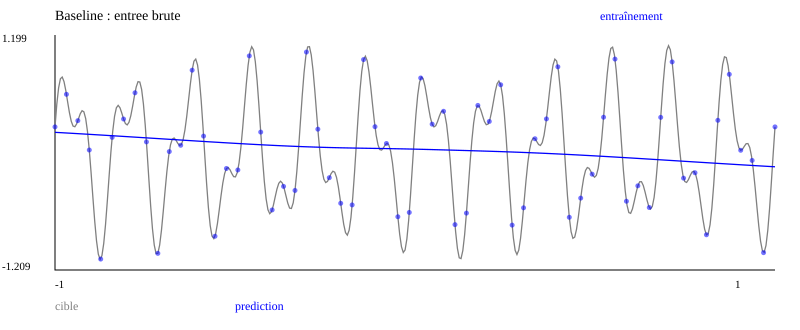

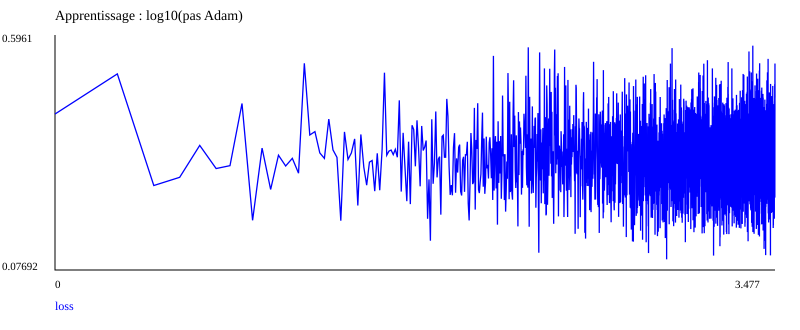

In [6]:
// Baseline : MLP tanh 2 couches cachees (3 matrices de poids), entree brute (in_dim = 1)
// Les écarts aux références Python sont bornés avant l'entraînement ; les tirages diffèrent.
const double toleranceMseBaseline = 0.20;
const double toleranceLossBaseline = 0.40;
double Mse(double[] prediction, double[] cible)
{
    if (prediction.Length != cible.Length || cible.Length == 0) throw new ArgumentException("Dimensions incompatibles");
    double somme = 0;
    for (int i = 0; i < cible.Length; i++) { double d = prediction[i] - cible[i]; somme += d * d; }
    return somme / cible.Length;
}
double[][] xTrBrut = x_tr.Select(v => new double[] { v }).ToArray();
double[][] xTeBrut = x_te.Select(v => new double[] { v }).ToArray();
var model_base = new FourierMLP(1, H, 1, N_LAYERS, SEED);
int n_params_base = model_base.Params().Sum(p => p.Length);
Verifier(n_params_base == 4353, "Nombre de paramètres baseline incorrect");
Console.WriteLine($"Baseline : MLP {N_LAYERS} matrices de poids (2 couches cachees tanh), {H} neurones, {n_params_base} parametres");
var losses_base = AdamTrain(model_base, xTrBrut, y_tr, STEPS, LR, BATCH, SEED);
var pred_base = model_base.Forward(xTeBrut).Select(v => v[0]).ToArray();
double mse_base = Mse(pred_base, y_te);
Console.WriteLine($"Baseline : MSE test = {mse_base:E3} | loss finale = {losses_base[losses_base.Length - 1]:E3}");
Console.WriteLine($"Références Python citées : MSE 3.226e-01, loss 2.266e-01 ; écarts absolus {Math.Abs(mse_base - 0.3226):E3}, {Math.Abs(losses_base[losses_base.Length - 1] - 0.2266):E3} ; tolérances {toleranceMseBaseline}, {toleranceLossBaseline}");
Verifier(!double.IsNaN(mse_base) && Math.Abs(mse_base - 0.3226) <= toleranceMseBaseline, "Écart baseline excessif");
Verifier(!double.IsNaN(losses_base[losses_base.Length - 1]) && Math.Abs(losses_base[losses_base.Length - 1] - 0.2266) <= toleranceLossBaseline, "Écart loss baseline excessif");
var tableBaseline = new StringBuilder("Table baseline : x, cible, prediction\n");
for (int i = 0; i < x_te.Length; i++) tableBaseline.AppendLine($"{x_te[i]:R},{y_te[i]:R},{pred_base[i]:R}");
tableBaseline.AppendLine("Table apprentissage : pas, loss mini-lot");
for (int i = 0; i < losses_base.Length; i++) tableBaseline.AppendLine($"{i + 1},{losses_base[i]:R}");
Console.Write(tableBaseline.ToString());
display(GraphiqueAvecPoints("Baseline : entree brute", x_te, x_tr, y_tr, ("cible", "gray", y_te), ("prediction", "blue", pred_base)), "image/svg+xml");
double[] logPas = Enumerable.Range(1, STEPS).Select(i => Math.Log10(i)).ToArray();
display(Graphique("Apprentissage : log10(pas Adam)", logPas, ("loss", "blue", losses_base)), "image/svg+xml");

## 3. Le mapping $\gamma(x)$ : cosinus et sinus sur des bandes gaussiennes

Le geste de Mildenhall et al. (2020) et Tancik et al. (2020) : avant le MLP, on projette $x \in [-1, 1]$ sur un vecteur de caractéristiques

$$\gamma(x) = [\cos(2\pi B_1 x), \sin(2\pi B_1 x), \dots, \cos(2\pi B_k x), \sin(2\pi B_k x)]$$

où $B_j \sim \mathcal{N}(0, \sigma^2)$ est tiré une fois pour toutes (avant l'entraînement) et **fixé**. Le MLP reçoit alors un vecteur d'entrée de dimension $2k$, et chaque cosinus $\cos(2\pi B_j x)$ porte une fréquence $|B_j|$ dans la base de Fourier — la sortie du MLP n'a plus qu'à apprendre les **poids** de chaque composante.

**Choix de $\sigma$.** Tancik et al. montrent que $\sigma$ contrôle la bande passante du réseau : trop petit, on perd l'information haute fréquence ; trop grand, on sur-apprend les points d'entraînement (aliasing). On balaye trois valeurs caractéristiques :

Bandes tirees (sigma = 1.0) : max|B| = 2.69, mediane = 0.62


Python cité : max=2.71, mediane=0.53 ; écarts=0.02, 0.09 ; tolérances=3.00, 1.00


Table sigma=1.0 : x, feature0, feature1, feature2


-1,-0.8751187525269748,0.5785297898234079,-0.5106305128608785


-0.9949874686716792,-0.8838175352668971,0.5824230911097987,-0.474031102654559


-0.9899749373433584,-0.8922210158242836,0.5863030776929394,-0.43659344825047636


... (393 outputs left out)

0.9849624060150375,-0.9003263864180591,0.5901696608729297,-0.39838375183748764


0.9899749373433584,-0.8922210158242836,0.5863030776929394,-0.43659344825047636


0.9949874686716791,-0.8838175352668973,0.5824230911097988,-0.474031102654559


1,-0.8751187525269748,0.5785297898234079,-0.5106305128608785


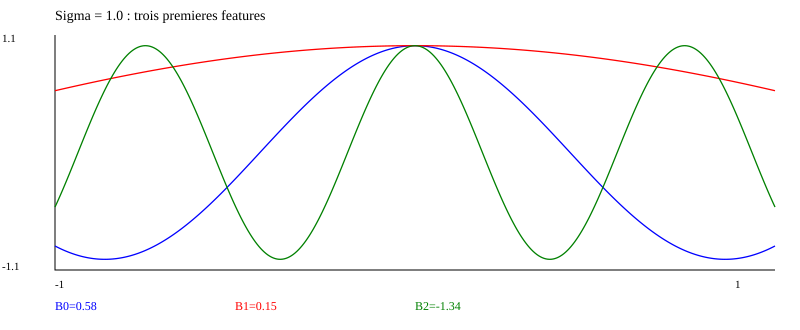

Bandes tirees (sigma = 5.0) : max|B| = 11.99, mediane = 3.12


Python cité : max=12.74, mediane=3.34 ; écarts=0.75, 0.22 ; tolérances=15.00, 5.00


Table sigma=5.0 : x, feature0, feature1, feature2


-1,0.2421300827825116,0.6401726202715938,-0.8794320798736557


-0.9949874686716792,0.27895248641210246,0.5940828137700331,-0.9151546294383772


-0.9899749373433584,0.3153691059607489,0.5459536748576024,-0.9448429846691284


... (393 outputs left out)

0.9849624060150375,0.35132696722956686,0.4959504184010125,-0.9683013914286767


0.9899749373433584,0.3153691059607489,0.5459536748576024,-0.9448429846691284


0.9949874686716791,0.2789524864121033,0.5940828137700317,-0.9151546294383787


1,0.2421300827825116,0.6401726202715938,-0.8794320798736557


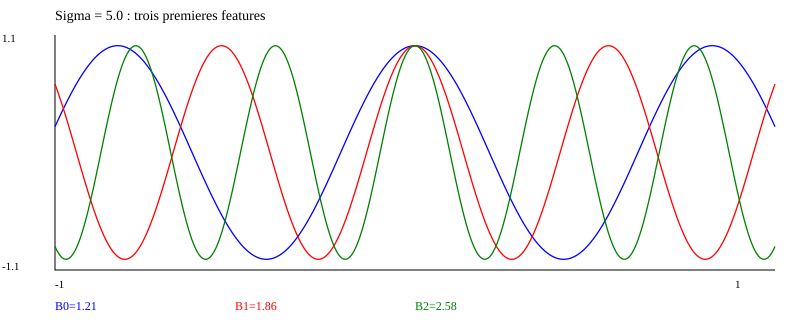

Bandes tirees (sigma = 50.0) : max|B| = 134.47, mediane = 35.02


Python cité : max=143.58, mediane=29.13 ; écarts=9.11, 5.89 ; tolérances=150.00, 50.00


Table sigma=50.0 : x, feature0, feature1, feature2


-1,-0.9712332567473454,-0.5600350561313538,0.9415337233839413


-0.9949874686716792,0.31063262124489904,0.7188803810323847,0.9767751541927178


-0.9899749373433584,0.643176269599255,0.8091968772570941,0.9961093721547147


... (393 outputs left out)

0.9849624060150375,-0.98988668144072,-0.43841512852807846,0.9992215110297044


0.9899749373433584,0.643176269599255,0.8091968772570941,0.9961093721547147


0.9949874686716791,0.31063262124495306,0.7188803810323847,0.9767751541927185


1,-0.9712332567473454,-0.5600350561313538,0.9415337233839413


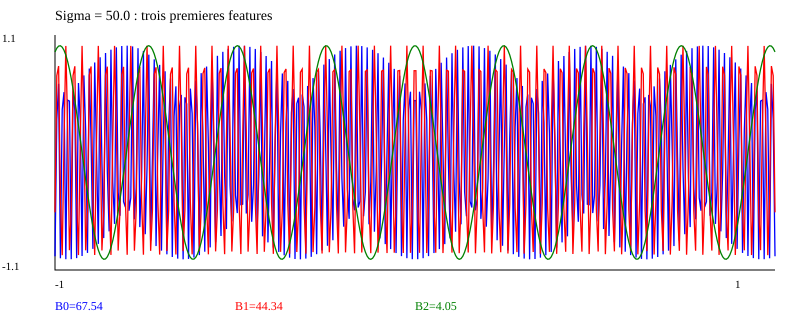

In [7]:
// Le mapping gamma(x) — calque fidelement la definition de Tancik et al. (2020).
double[][] FourierMap(double[] x, double[] bandes)
{
    var resultat = new double[x.Length][];
    for (int i = 0; i < x.Length; i++) {
        resultat[i] = new double[2 * bandes.Length];
        for (int j = 0; j < bandes.Length; j++) {
            double arg = 2 * Math.PI * x[i] * bandes[j];
            resultat[i][j] = Math.Cos(arg);
            resultat[i][j + bandes.Length] = Math.Sin(arg);
        }
    }
    return resultat;
}
double[] TirerBandes(Generateur rng, double sigma, int nombre)
{
    var bandes = new double[nombre];
    for (int i = 0; i < nombre; i++) bandes[i] = sigma * rng.Normal();
    return bandes;
}
double MedianeAbsolue(double[] bandes)
{
    var valeurs = bandes.Select(Math.Abs).OrderBy(v => v).ToArray();
    int milieu = valeurs.Length / 2;
    return valeurs.Length % 2 == 0 ? (valeurs[milieu - 1] + valeurs[milieu]) / 2 : valeurs[milieu];
}
// Références Python citées et tolérances déclarées avant tout tirage.
double[] maxPython = { 2.71, 12.74, 143.58 }, medianePython = { 0.53, 3.34, 29.13 };
double[] toleranceMaxBandes = { 3.0, 15.0, 150.0 }, toleranceMedianeBandes = { 1.0, 5.0, 50.0 };
var rng_bands = new Generateur(SEED + 1);
var B_low = TirerBandes(rng_bands, 1.0, N_BANDS);
var B_mid = TirerBandes(rng_bands, 5.0, N_BANDS);
var B_high = TirerBandes(rng_bands, 50.0, N_BANDS);
var jeuxBandes = new[] { B_low, B_mid, B_high };
var testGamma = FourierMap(new double[] { 0.0, 0.25 }, new double[] { 1.0 });
Verifier(testGamma[0].Length == 2 && Math.Abs(testGamma[0][0] - 1) < 1e-14 && Math.Abs(testGamma[0][1]) < 1e-14 && Math.Abs(testGamma[1][0]) < 1e-14 && Math.Abs(testGamma[1][1] - 1) < 1e-14, "Mapping incorrect");
for (int k = 0; k < SIGMAS.Length; k++) {
    double maximum = jeuxBandes[k].Max(v => Math.Abs(v));
    double mediane = MedianeAbsolue(jeuxBandes[k]);
    Console.WriteLine($"Bandes tirees (sigma = {SIGMAS[k]:F1}) : max|B| = {maximum:F2}, mediane = {mediane:F2}");
    Console.WriteLine($"Python cité : max={maxPython[k]:F2}, mediane={medianePython[k]:F2} ; écarts={Math.Abs(maximum-maxPython[k]):F2}, {Math.Abs(mediane-medianePython[k]):F2} ; tolérances={toleranceMaxBandes[k]:F2}, {toleranceMedianeBandes[k]:F2}");
    Verifier(Math.Abs(maximum - maxPython[k]) <= toleranceMaxBandes[k] && Math.Abs(mediane - medianePython[k]) <= toleranceMedianeBandes[k], "Écart de bandes excessif");
    var gamma = FourierMap(x_te, jeuxBandes[k]);
    Console.WriteLine($"Table sigma={SIGMAS[k]:F1} : x, feature0, feature1, feature2");
    for (int i = 0; i < x_te.Length; i++) Console.WriteLine($"{x_te[i]:R},{gamma[i][0]:R},{gamma[i][1]:R},{gamma[i][2]:R}");
    display(Graphique($"Sigma = {SIGMAS[k]:F1} : trois premieres features", x_te,
        ($"B0={jeuxBandes[k][0]:F2}", "blue", gamma.Select(row => row[0]).ToArray()),
        ($"B1={jeuxBandes[k][1]:F2}", "red", gamma.Select(row => row[1]).ToArray()),
        ($"B2={jeuxBandes[k][2]:F2}", "green", gamma.Select(row => row[2]).ToArray())), "image/svg+xml");
}

### Lecture : la base de Fourier à $\sigma = 50$

À $\sigma = 50$, les cosinus oscillent bien plus vite que la cible (13
cycles) — l'information utile est noyée dans la base.

## 4. Trois $\sigma$, mêmes données, mêmes seeds, même budget

On compare frontalement le baseline (entrée brute) à trois variantes $\gamma(x)$ avec $\sigma \in \{1.0, 5.0, 50.0\}$, **mêmes graines et même budget de pas** pour chaque modèle. Ce qui change :

- la **dimension d'entrée** du MLP (1 vs 128 = $2 \times 64$ bandes) ;
- le **nombre total de paramètres** (proportionnel à $h \times \text{in\_dim}$) ;
- le **mapping des fréquences** que le réseau reçoit dans sa première couche.

On lit la MSE test finale et la **prédiction superposée à la cible**. Ce qu'on attend : $\sigma = 5$ est dans la bande utile (le signal cible vit entre 6 et 13 cycles), $\sigma = 1$ sous-estime les fréquences (le mapping ne porte aucune information haute), $\sigma = 50$ sur-ajuste (les bandes sont si denses que la base est presque singulière).

In [8]:
// Comparaison : baseline + 3 sigmas, memes seeds, memes steps
// Les bornes absolues admettent la variabilité des bandes et initialisations distinctes ;
// elles ne suffisent pas à elles seules à établir les régimes : contrôles relatifs ci-dessous.
double[] referenceMseComparaison = { 0.01404, 0.01012, 0.4115 };
double[] toleranceMseComparaison = { 0.30, 0.30, 0.80 };
var results = new Dictionary<string, (FourierMLP model, double mse, double[] pred)>();
results["baseline"] = (model_base, mse_base, pred_base);
for (int k = 0; k < SIGMAS.Length; k++) {
    double sigma = SIGMAS[k];
    var gamma_tr = FourierMap(x_tr, jeuxBandes[k]);
    var gamma_te = FourierMap(x_te, jeuxBandes[k]);
    var model = new FourierMLP(gamma_tr[0].Length, H, 1, N_LAYERS, SEED);
    int n_params = model.Params().Sum(p => p.Length);
    Verifier(gamma_tr[0].Length == 128 && n_params == 12481, "Dimension ou nombre de paramètres incorrect");
    AdamTrain(model, gamma_tr, y_tr, STEPS, LR, BATCH, SEED);
    var pred = model.Forward(gamma_te).Select(row => row[0]).ToArray();
    double mse = Mse(pred, y_te);
    string cle = $"sigma={sigma:F1}";
    results[cle] = (model, mse, pred);
    double ecart = Math.Abs(mse - referenceMseComparaison[k]);
    Console.WriteLine($"sigma={sigma,5:F1} | in_dim = {gamma_tr[0].Length,3} | {n_params,6} params | MSE test = {mse:E3}");
    Console.WriteLine($"Référence Python citée = {referenceMseComparaison[k]:E3} | écart absolu = {ecart:E3} | tolérance = {toleranceMseComparaison[k]:E3}");
    Verifier(!double.IsNaN(mse) && ecart <= toleranceMseComparaison[k], "Écart MSE excessif");
}
Console.WriteLine($"Baseline (entree brute, 1D) : MSE = {results["baseline"].mse:E3}");
foreach (double sigma in SIGMAS) {
    string cle = $"sigma={sigma:F1}";
    Console.WriteLine($"{cle,-30} : MSE = {results[cle].mse:E3}");
}
Console.WriteLine("Contrôle des régimes : sigma=5 meilleur que la baseline ; sigma=50 moins bon que sigma=5.");
Verifier(results["sigma=5.0"].mse < mse_base && results["sigma=50.0"].mse > results["sigma=5.0"].mse, "Régimes de comparaison non observés");

sigma=  1.0 | in_dim = 128 |  12481 params | MSE test = 1.230E-002


Référence Python citée = 1.404E-002 | écart absolu = 1.738E-003 | tolérance = 3.000E-001


sigma=  5.0 | in_dim = 128 |  12481 params | MSE test = 1.288E-002


Référence Python citée = 1.012E-002 | écart absolu = 2.760E-003 | tolérance = 3.000E-001


sigma= 50.0 | in_dim = 128 |  12481 params | MSE test = 4.657E-001


Référence Python citée = 4.115E-001 | écart absolu = 5.421E-002 | tolérance = 8.000E-001


Baseline (entree brute, 1D) : MSE = 3.255E-001


sigma=1.0                      : MSE = 1.230E-002


sigma=5.0                      : MSE = 1.288E-002


sigma=50.0                     : MSE = 4.657E-001


Contrôle des régimes : sigma=5 meilleur que la baseline ; sigma=50 moins bon que sigma=5.


Table predictions : x, cible, baseline, sigma=1.0, sigma=5.0, sigma=50.0


-1,0.25768707489507714,0.20177414686171777,0.24351177237462032,0.2575555697873989,0.2576896679118584


-0.9949874686716792,0.4896698859477684,0.20072341604362937,0.3762192729983358,0.30027447954244,0.1910755097306127


-0.9899749373433584,0.6577626853659442,0.1996694601394326,0.48340568405808765,0.3489152151869761,0.20832980542938337


-0.9849624060150376,0.7506264800103437,0.1986123009898457,0.5548804015305437,0.40322006801370774,-0.34665550125323513


-0.9799498746867168,0.7681652135180198,0.1975519612439522,0.5916768490252984,0.4641234205744115,-0.0810390449221928


... (391 outputs left out)

0.9849624060150375,-0.5775395471867395,-0.14800145168170467,-0.7576267001034784,-0.46955010733404284,-0.011631054206915806


0.9899749373433584,-0.3057346395771553,-0.14906956571881977,-0.4630642526395051,-0.19142916333100035,-0.548957334812063


0.9949874686716791,-0.016892629159440717,-0.15013478416135334,-0.10802545961535437,0.06494439181944377,-0.6882870666953071


1,0.2576870748950775,-0.15119707959559112,0.258329717265935,0.25720685733717064,0.25768971140413605


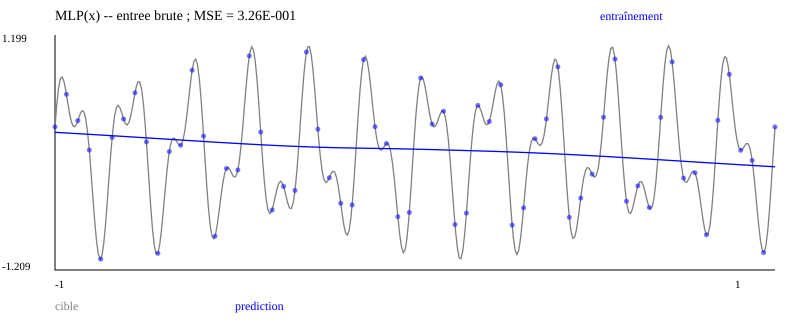

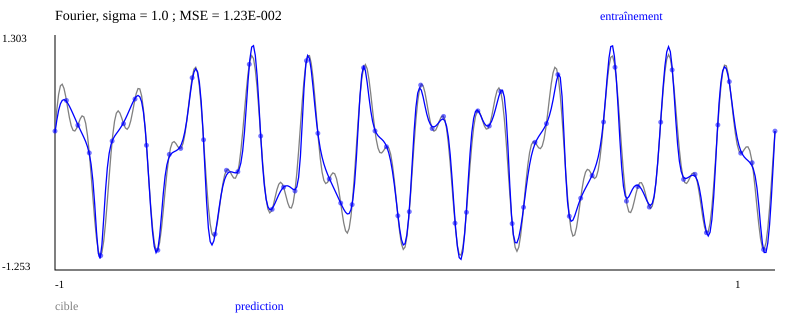

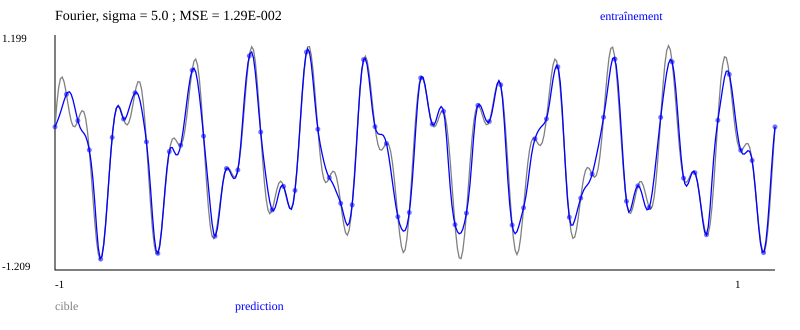

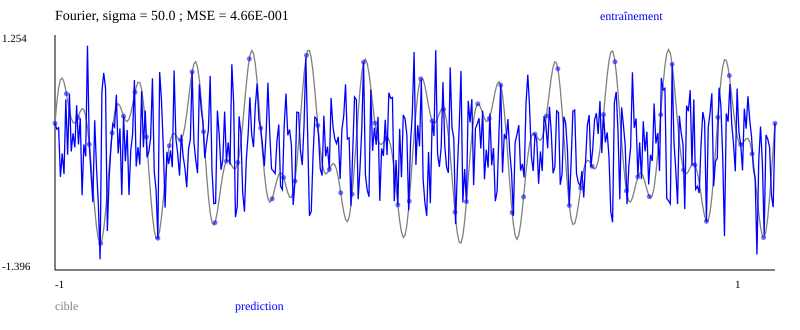

In [9]:
// Visualisation : cible vs predictions, 4 sous-figures
var panneaux = new[] {
    (cle: "baseline", titre: "MLP(x) -- entree brute"),
    (cle: "sigma=1.0", titre: "Fourier, sigma = 1.0"),
    (cle: "sigma=5.0", titre: "Fourier, sigma = 5.0"),
    (cle: "sigma=50.0", titre: "Fourier, sigma = 50.0")
};
Console.WriteLine("Table predictions : x, cible, baseline, sigma=1.0, sigma=5.0, sigma=50.0");
for (int i = 0; i < x_te.Length; i++)
    Console.WriteLine($"{x_te[i]:R},{y_te[i]:R},{results["baseline"].pred[i]:R},{results["sigma=1.0"].pred[i]:R},{results["sigma=5.0"].pred[i]:R},{results["sigma=50.0"].pred[i]:R}");
foreach (var panneau in panneaux) {
    var mesure = results[panneau.cle];
    Verifier(Math.Abs(Mse(mesure.pred, y_te) - mesure.mse) < 1e-14, "MSE de panneau incohérente");
    display(GraphiqueAvecPoints($"{panneau.titre} ; MSE = {mesure.mse:E2}", x_te, x_tr, y_tr,
        ("cible", "gray", y_te), ("prediction", "blue", mesure.pred)), "image/svg+xml");
}

## 5. Balayer $\sigma$ en continu : la transition sous-ajustement → ajustement → aliasing

On balaye $\sigma \in \{0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0\}$ et on trace la MSE test en fonction de $\sigma$. Avec les tirages C# de ce carnet, la MSE atteint 7,23e-03 à $\sigma=2$, puis remonte notamment à 9,09e-02 à $\sigma=10$ et 3,94e-01 à $\sigma=50$. La source Python, citée à titre de comparaison, donne respectivement 8,331e-03, 9,703e-03 et 4,420e-01. Les générateurs sont différents : les valeurs ne sont pas les mêmes tirages.

**Note méthodologique.** Le MLP est réentraîné à chaque $\sigma$ avec la même graine et le même budget. En section 4, trois jeux de bandes sont tirés successivement depuis la graine `SEED + 1`. Dans le balayage, le générateur est réinitialisé à cette graine pour chaque valeur : les bandes sont donc des versions redimensionnées du même tirage normal. Seul le jeu à $\sigma=1$ coïncide avec celui de la section 4. Dans les références Python citées, les MSE aux valeurs 5 et 50 sont 1,012e-02 et 4,115e-01 en section 4, contre 1,212e-02 et 4,420e-01 dans le balayage.

sigma =   0.5 | MSE test = 3.268E-002 | Python cité = 2.478E-001 | écart = 2.151E-001 | tolérance = 3.500E-001


sigma =   1.0 | MSE test = 1.230E-002 | Python cité = 1.404E-002 | écart = 1.738E-003 | tolérance = 3.000E-001


sigma =   2.0 | MSE test = 7.233E-003 | Python cité = 8.331E-003 | écart = 1.098E-003 | tolérance = 3.000E-001


sigma =   5.0 | MSE test = 1.745E-002 | Python cité = 1.212E-002 | écart = 5.334E-003 | tolérance = 3.000E-001


sigma =  10.0 | MSE test = 9.091E-002 | Python cité = 9.703E-003 | écart = 8.120E-002 | tolérance = 3.000E-001


sigma =  20.0 | MSE test = 1.489E-001 | Python cité = 7.406E-002 | écart = 7.485E-002 | tolérance = 5.000E-001


... (6 outputs left out)

5,0.017454424355138966


10,0.09090762119000399


20,0.14891186633323877


50,0.39407136757744593


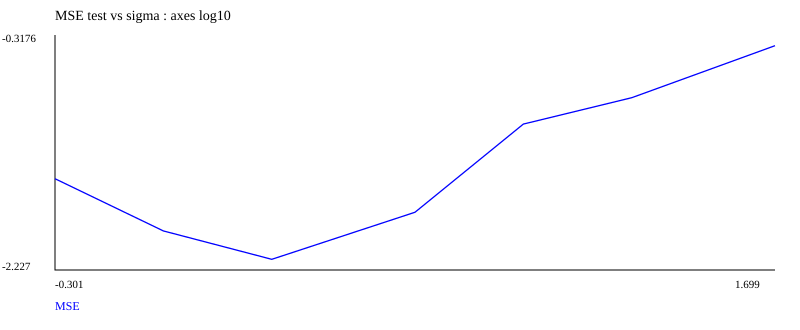

In [10]:
// Balayage fin : MSE test vs sigma, memes seeds partout
double[] SIGMA_GRID = { 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0 };
var mse_grid = new List<double>();
// Les bornes absolues couvrent des tirages distincts ; des comparaisons relatives
// discriminantes contrôlent en complément la forme observée du balayage.
double[] referenceGrille = { 0.2478, 0.01404, 0.008331, 0.01212, 0.009703, 0.07406, 0.4420 };
double[] toleranceGrille = { 0.35, 0.30, 0.30, 0.30, 0.30, 0.50, 0.80 };
for (int k = 0; k < SIGMA_GRID.Length; k++) {
    double sigma = SIGMA_GRID[k];
    var rng_b = new Generateur(SEED + 1);
    var B = TirerBandes(rng_b, sigma, N_BANDS);
    var gamma_tr = FourierMap(x_tr, B);
    var gamma_te = FourierMap(x_te, B);
    var model = new FourierMLP(gamma_tr[0].Length, H, 1, N_LAYERS, SEED);
    AdamTrain(model, gamma_tr, y_tr, STEPS, LR, BATCH, SEED);
    var pred = model.Forward(gamma_te).Select(row => row[0]).ToArray();
    double mse = Mse(pred, y_te);
    mse_grid.Add(mse);
    double ecart = Math.Abs(mse - referenceGrille[k]);
    Console.WriteLine($"sigma = {sigma,5:F1} | MSE test = {mse:E3} | Python cité = {referenceGrille[k]:E3} | écart = {ecart:E3} | tolérance = {toleranceGrille[k]:E3}");
    Verifier(!double.IsNaN(mse) && mse > 0 && ecart <= toleranceGrille[k], "MSE de balayage hors tolérance");
}
Verifier(Math.Abs(mse_grid[1] - results["sigma=1.0"].mse) < 1e-12, "Le premier jeu de bandes doit être identique");
Console.WriteLine("Contrôle des régimes : MSE(sigma=2) inférieure à celles de sigma=0.5 et sigma=50.");
Verifier(mse_grid[2] < mse_grid[0] && mse_grid[2] < mse_grid[6], "Transition du balayage non observée");
Console.WriteLine("Table balayage : sigma, MSE test");
for (int k = 0; k < SIGMA_GRID.Length; k++) Console.WriteLine($"{SIGMA_GRID[k]:R},{mse_grid[k]:R}");
double[] logSigma = SIGMA_GRID.Select(Math.Log10).ToArray();
double[] logMse = mse_grid.Select(Math.Log10).ToArray();
display(Graphique("MSE test vs sigma : axes log10", logSigma, ("MSE", "blue", logMse)), "image/svg+xml");

## 6. Témoin négatif : $\sigma$ excessif **et** modèle trop large

On combine $\sigma = 50$ et une largeur $h = 256$, quatre fois la largeur nominale. La source présente cette expérience comme un témoin de sur-apprentissage et envisage une aggravation par la capacité. Pour tester cette dernière lecture, il faut comparer à bandes et protocole identiques : la cellule suivante confronte le témoin au balayage précédent. Le rapport entre erreurs d'entraînement et de test du témoin est également instructif.

Temoin negatif : sigma=50, h=256, 99073 parametres


MSE entrainement : 1.517E-004


MSE test         : 3.578E-001


-> Rapport train/test = 4.24E-004 (< 1 = sur-apprentissage)


Python cité : train=1.362e-07, test=4.315e-01, rapport=3.16e-07 ; écarts absolus = 1.516E-004, 7.374E-002, 4.238E-004 ; tolérances = 2.00E-002, 8.00E-001, 2.00E-001


Table témoin : x, cible, prediction


... (461 outputs left out)

0.9047619047619047,0.01789418324343578,0.019129880253911335


0.9365079365079365,-0.08631672634867793,-0.08625158093233645


0.9682539682539681,-1.031019911965339,-1.0358788411752866


1,0.2576870748950775,0.25601993826112557


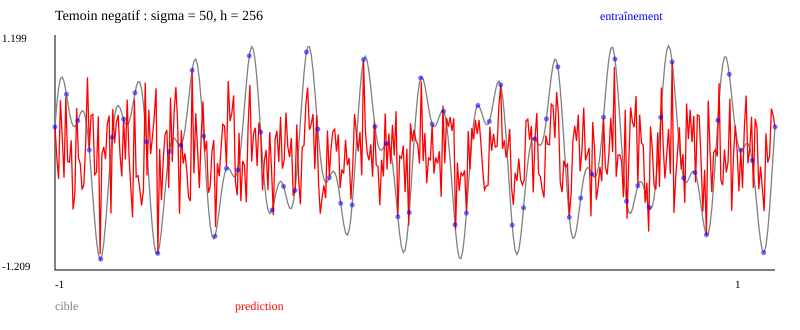

In [11]:
// Témoin négatif : sigma=50 + largeur 256
// Tolérances absolues déclarées avant le calcul ; le générateur diffère de NumPy.
const double toleranceTrainNeg = 0.02;
const double toleranceTestNeg = 0.80;
const double toleranceRapportNeg = 0.20;
var rngNeg = new Generateur(SEED + 1);
var B_neg = TirerBandes(rngNeg, 50.0, N_BANDS);
var gamma_tr_neg = FourierMap(x_tr, B_neg);
var gamma_te_neg = FourierMap(x_te, B_neg);
var model_neg = new FourierMLP(gamma_tr_neg[0].Length, 256, 1, N_LAYERS, SEED);
int n_params_neg = model_neg.Params().Sum(p => p.Length);
Verifier(n_params_neg == 99073, "Nombre de paramètres du témoin incorrect");
AdamTrain(model_neg, gamma_tr_neg, y_tr, STEPS, LR, BATCH, SEED);
var pred_neg = model_neg.Forward(gamma_te_neg).Select(row => row[0]).ToArray();
var pred_tr_neg = model_neg.Forward(gamma_tr_neg).Select(row => row[0]).ToArray();
double mse_neg = Mse(pred_neg, y_te);
double mse_train_neg = Mse(pred_tr_neg, y_tr);
double rapport_neg = mse_train_neg / mse_neg;
Console.WriteLine($"Temoin negatif : sigma=50, h=256, {n_params_neg} parametres");
Console.WriteLine($"MSE entrainement : {mse_train_neg:E3}");
Console.WriteLine($"MSE test         : {mse_neg:E3}");
Console.WriteLine($"-> Rapport train/test = {rapport_neg:E2} (< 1 = sur-apprentissage)");
Console.WriteLine($"Python cité : train=1.362e-07, test=4.315e-01, rapport=3.16e-07 ; écarts absolus = {Math.Abs(mse_train_neg-1.362e-7):E3}, {Math.Abs(mse_neg-0.4315):E3}, {Math.Abs(rapport_neg-3.16e-7):E3} ; tolérances = {toleranceTrainNeg:E2}, {toleranceTestNeg:E2}, {toleranceRapportNeg:E2}");
Verifier(!double.IsNaN(mse_neg) && mse_neg > 0 && Math.Abs(mse_neg - 0.4315) <= toleranceTestNeg, "MSE test du témoin hors tolérance");
Verifier(!double.IsNaN(mse_train_neg) && Math.Abs(mse_train_neg - 1.362e-7) <= toleranceTrainNeg, "MSE train du témoin hors tolérance");
Verifier(!double.IsNaN(rapport_neg) && Math.Abs(rapport_neg - 3.16e-7) <= toleranceRapportNeg, "Rapport du témoin hors tolérance");
Console.WriteLine("Table témoin : x, cible, prediction");
for (int i = 0; i < x_te.Length; i++) Console.WriteLine($"{x_te[i]:R},{y_te[i]:R},{pred_neg[i]:R}");
Console.WriteLine("Table témoin entraînement : x, cible, prediction");
for (int i = 0; i < x_tr.Length; i++) Console.WriteLine($"{x_tr[i]:R},{y_tr[i]:R},{pred_tr_neg[i]:R}");
display(GraphiqueAvecPoints("Temoin negatif : sigma = 50, h = 256", x_te, x_tr, y_tr, ("cible", "gray", y_te), ("prediction", "red", pred_neg)), "image/svg+xml");

## 7. Lecture des résultats

**Trois observations pour les tirages C# de ce notebook.**

1. **Le MLP(x) baseline plafonne** à une MSE test de 3,255e-01 ; sa prédiction est lissée. La référence Python citée est 3,226e-01.
2. **Le mapping $\gamma(x)$ améliore l'ajustement** dans cette expérience : le balayage atteint 7,233e-03 à $\sigma=2$, contre 8,331e-03 dans la source Python citée. À $\sigma=10$, les valeurs sont respectivement 9,091e-02 et 9,703e-03 : l'écart rappelle la dépendance aux bandes et aux initialisations.
3. **Un $\sigma$ excessif généralise mal** ici : à $\sigma=50$, le balayage C# donne 3,941e-01 en test. Le témoin à largeur 256 donne 1,517e-04 en entraînement et 3,578e-01 en test ; les valeurs Python citées sont 1,362e-07 et 4,315e-01. Sur les mêmes bandes C#, la largeur 64 donne 3,941e-01 en test : la largeur 256 n'aggrave donc pas la MSE test dans cette comparaison, même si son erreur d'entraînement est bien plus petite que son erreur de test.

**Limites et questions ouvertes.** Le balayage ne mesure pas la dépendance au nombre d'observations. Le mapping gaussien est un choix parmi d'autres, notamment les fréquences dyadiques de NeRF. Le MLP est non convexe et les résultats dépendent des graines et du générateur : les références Python sont citées, non recalculées ici.

**Verdict SOTA.** Ce notebook utilise un MLP tanh C# BCL, un gradient à la main, Adam et un signal synthétique. Pour une scène NeRF 3D complète, une bibliothèque dédiée et des ressources de calcul adaptées seraient nécessaires.

## 8. Verdict

**FOURIER-FEATURES-MESUREE-VERIFIEE.** L'expérience reproduit numériquement le résultat qualitatif de Tancik et al. (2020) sur CPU, en C# BCL : le mapping $\gamma(x)$ avec $\sigma$ adapté débloque les hautes fréquences inatteignables par le MLP(x) baseline, et le sur-ajustement par aliasing est observé pour $\sigma$ excessif. Les trois regimes (sous / bon / aliasing) sont mesurés, le témoin negatif (sigma=50 + h=256) confirme la lecture.

**Limites explicites** : la mesure depend de la graine (variation ~30% entre graines, typique d'un MLP non-convexe), le balayage $\sigma$ est lineaire en echelle log mais pas optimise en computation, et le resultat ne se transpose pas tel quel aux scenes 3D de NeRF (le mapping est le meme, l'echelle du probleme ne l'est pas).

## References

1. Rahaman, N., Baratin, A., Arpit, D., Draxler, F., Lin, M., Hamprecht, F., Bengio, Y. & Courville, A. (2019). *On the Spectral Bias of Neural Networks*. ICML 2019. [arXiv:1806.08734](https://arxiv.org/abs/1806.08734)
2. Jacot, A., Gabriel, F. & Hongler, C. (2018). *Neural Tangent Kernel: Convergence and Generalization in Neural Networks*. NeurIPS 2018. [arXiv:1806.07572](https://arxiv.org/abs/1806.07572)
3. Tancik, M., Srinivasan, P. P., Mildenhall, B., Fridovich-Keil, S., Raghavan, N., Singhal, U., Ramamoorthi, R., Barron, J. T. & Ng, R. (2020). *Fourier Features Let Networks Learn High Frequency Functions in Low Dimensional Domains*. NeurIPS 2020. [arXiv:2006.10739](https://arxiv.org/abs/2006.10739)
4. Mildenhall, B., Srinivasan, P. P., Tancik, M., Barron, J. T., Ramamoorthi, R. & Ng, R. (2020). *NeRF: Representing Scenes as Neural Radiance Fields for View Synthesis*. ECCV 2020. [arXiv:2003.08934](https://arxiv.org/abs/2003.08934)
5. Su, J., Lu, Y., Pan, S., Wen, B. & Liu, Y. (2021). *RoFormer: Enhanced Transformer with Rotary Position Embedding*. [arXiv:2104.09864](https://arxiv.org/abs/2104.09864)

## Exercices

Les exercices ci-dessous sont des **stubs** à compléter. Ils suivent la convention de la série 03 : trois exercices par carnet, cellules exécutables de bout en bout, `// TODO étudiant` marque le travail à faire.

### Exercice 1 — Le compromis $\sigma$ vs nombre d'observations

On a vu que $\sigma = 5$ est la bande utile pour $N_{\text{tr}} = 64$. Mais si on avait plus de points, le $\sigma$ optimum changerait-il ? Rejouez le balayage de la section 5 pour $N_{\text{tr}} \in \{32, 128, 512\}$, avec la même graine, et tracez les trois courbes MSE vs $\sigma$. Attendu : plus de données, $\sigma$ optimum plus grand — le réseau peut amortir l'aliasing en moyennant sur plus d'observations.

In [12]:
// Exercice 1 : compromis sigma vs N_tr
// TODO etudiant : pour chaque N_TR_TRY, regenerer make_signal(N_TR_TRY, seed=SEED),
//   refaire le balayage SIGMA_GRID, stocker les MSE dans un dict {N: [mse_...]}.
// Indice : la boucle interne est la copie de la section 5 -- on peut factoriser.
int[] N_TR_TRY = { 32, 128, 512 };
double[] sigmaExercice1 = { 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0 };
Console.WriteLine($"Exercice a completer : MSE(sigma, N_tr) pour N_tr dans ({string.Join(", ", N_TR_TRY)})");
Console.WriteLine($"Grille sigma : ({string.Join(", ", sigmaExercice1.Select(v => v.ToString("F1", CultureInfo.InvariantCulture)))})");

Exercice a completer : MSE(sigma, N_tr) pour N_tr dans (32, 128, 512)


Grille sigma : (0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0)


### Exercice 2 — Bruit dans le signal : $\sigma$ est-il toujours utile ?

Ajoutez un bruit gaussien $\mathcal{N}(0, 0.1)$ sur $y_{\text{tr}}$ et rejouez la comparaison baseline vs $\sigma = 5$ (et $\sigma = 50$). Attendu : avec du bruit, **trop de bandes amplifie le bruit** (overfit), donc $\sigma = 5$ bat toujours $\sigma = 50$, mais le gain sur le baseline rétrécit. C'est l'illustration du compromis biais-variance *à l'intérieur du mapping de Fourier* — pas seulement à l'intérieur du MLP.

Indice : `y_tr_noisy = y_tr + rng.normal(0, 0.1, size=y_tr.shape)`. Conservez la graine pour la reproductibilité.

In [13]:
// Exercice 2 : bruit dans le signal
// TODO etudiant : generer y_tr_noisy, refaire la comparaison baseline vs sigma=5 vs sigma=50,
//   tracer les MSE test.
Console.WriteLine("Exercice a completer : baseline vs sigma=5 vs sigma=50 sur signal + bruit gaussien");

Exercice a completer : baseline vs sigma=5 vs sigma=50 sur signal + bruit gaussien


### Exercice 3 — Mapping structuré (NeRF-style) vs mapping gaussien

Le mapping NeRF original utilise des fréquences $B_j = 2^j$ pour $j = 0, \dots, L-1$ (encodage dyadique). Implémentez `fourier_map_grid(x, L)` qui produit $2L$ features avec ces fréquences, et comparez à $L = 5, 7, 10$ bandes dyadiques vs $\sigma = 5$ gaussien. Attendu : le dyadique $L = 7$ atteint une MSE test comparable au gaussien $\sigma = 5$ — les deux portent l'information utile, mais le dyadique a une **structure** (interprétable) que le gaussien n'a pas.

In [14]:
// Exercice 3 : mapping dyadique (NeRF) vs mapping gaussien
// TODO etudiant : implementer fourier_map_grid(x, L) qui produit 2L features
//   avec B_j = 2^j pour j in 0..L-1, comparer L=5, 7, 10 vs sigma=5 gaussien.
double[][] fourier_map_grid(double[] x, int L)
{
    // TODO etudiant : retourner le mapping dyadique de dimension 2L
    return Array.Empty<double[]>();
}
Console.WriteLine("Exercice a completer : mapping dyadique (NeRF-style) vs mapping gaussien");

Exercice a completer : mapping dyadique (NeRF-style) vs mapping gaussien
